# Polychromatic LGS with 589 + 569 nm pump

In [ ]:
from pylgs.all import *

In [ ]:
import logging
logging.getLogger().setLevel(logging.INFO)

## Without repump

`LGSSystem` loads the equations for an atomic system and sets values of parameters that are intended to be held fixed. Here we load a system that includes 589 nm and 569 nm pump light and fix all parameters except the detuning of 569 nm:

In [ ]:
lgs = LGSSystem(
    'Na589+569', 
    {
        'IntensitySI1': 50.,                # Light intensity of the 589 nm laser in the mesosphere in W/m^2
        'EllipticityDegrees1': 45.,         # Ellipticity of the 589 nm laser in degrees
        'PolarizationAngleDegrees1': 0,     # Polarization angle of the 589 nm laser in degrees
        'DetuningHz1': 1.0832e9,            # Detuning of the 589 nm laser in Hz
        'LaserWidthHz1': 10.0e6,            # Laser width of the 589 nm laser in Hz
        'IntensitySI2': 100.,               # Light intensity of the 569 nm laser in the mesosphere in W/m^2
        'EllipticityDegrees2': 45.,         # Ellipticity of the 569 nm laser in degrees
        'PolarizationAngleDegrees2': 0,     # Polarization angle of the 569 nm laser in degrees
        # 'DetuningHz2': 1.1e8,             # Detuning of the 569 nm laser in Hz
        'LaserWidthHz2': 10.0e6,            # Laser width of the 569 nm laser in Hz
        'BFieldG': 0.5,                     # Mesospheric magnetic field strength in Gauss
        'MagneticZenithDegrees': 45.,       # Zenith angle of the mesospheric magnetic field relative to the laser propagation direction in degrees
        'MagneticAzimuthDegrees': 45.,      # Azimuth angle of the mesospheric magnetic field relative to the laser propagation direction in degrees
        'SDampingCollisionRatePerS': 4081.63, # Spin damping collision rate in the mesosphere in s^-1
        'BeamTransitRatePerS': 131.944,     # Transit rate of atoms through the laser beam in s^-1
        'VccRatePerS': 28571.,              # Velocity-changing collision rate in the mesosphere in s^-1
        'TemperatureK': 185.,               # Temperature of the mesosphere in Kelvin
        'RecoilParameter': 1.               # Set to 1 to include recoil effects in the simulation, 0 to ignore them
    }
)

Print info about the atomic system:

In [ ]:
LGSSystem.info('Na589+569')

#### Atomic levels
$\text{3S}_{\frac{1}{2}}$, $\text{3P}_{\frac{1}{2}}$, $\text{3P}_{\frac{3}{2}}$, $\text{4S}_{\frac{1}{2}}$, $\text{4P}_{\frac{3}{2}}$, $\text{4D}_{\frac{5}{2}}$
#### Pump transitions
1. $\text{3S}_{\frac{1}{2}}\to \text{3P}_{\frac{3}{2}}$
1. $\text{3P}_{\frac{3}{2}}\to \text{4D}_{\frac{5}{2}}$
#### Transition wavelengths
- $\text{3P}_{\frac{1}{2}}\to \text{3S}_{\frac{1}{2}}$: 589.756 nm
- $\text{3P}_{\frac{3}{2}}\to \text{3S}_{\frac{1}{2}}$: 589.158 nm
- $\text{4P}_{\frac{3}{2}}\to \text{3S}_{\frac{1}{2}}$: 330.332 nm
- $\text{4S}_{\frac{1}{2}}\to \text{3P}_{\frac{1}{2}}$: 1138.46 nm
- $\text{4S}_{\frac{1}{2}}\to \text{3P}_{\frac{3}{2}}$: 1140.69 nm
- $\text{4D}_{\frac{5}{2}}\to \text{3P}_{\frac{3}{2}}$: 568.978 nm
- $\text{4P}_{\frac{3}{2}}\to \text{4S}_{\frac{1}{2}}$: 2206.24 nm
- $\text{4D}_{\frac{5}{2}}\to \text{4P}_{\frac{3}{2}}$: 2338.55 nm
#### Substructure
- Hyperfine structure included
- Zeeman structure included
- 80 total sublevels
#### Density matrix elements
- All populations included
- All Zeeman coherences (between same level and same F) included
- All hyperfine coherences (between same level and different F) neglected
- Optical coherences (between different levels) included for pump transitions only
- 1842 total density matrix elements
#### Input parameters
- BeamTransitRatePerS
- BFieldG
- MagneticAzimuthDegrees
- MagneticZenithDegrees
- RecoilParameter
- SDampingCollisionRatePerS
- TemperatureK
- VccRatePerS
- DetuningHz2
- DetuningHz1
- EllipticityDegrees2
- EllipticityDegrees1
- IntensitySI2
- IntensitySI1
- LaserWidthHz2
- LaserWidthHz1
- PolarizationAngleDegrees2
- PolarizationAngleDegrees1

A level diagram drawn to scale that neglects hyperfine and Zeeman structure:

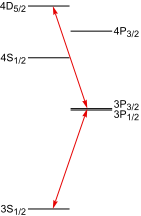

In [ ]:
LGSSystem.diagram('Na589+569', "Toy")

A level diagram, including hyperfine and Zeeman structure, not to scale:

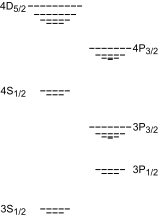

In [ ]:
LGSSystem.diagram('Na589+569', "NotToScale")

Create an adaptively refined model assuming a particular value of the 569 nm detuning by repeatedly subdividing velocity groups with the highest estimated local error until a specified relative global error estimate `rtol` is achieved. We return the results of the intermediate models so that we can illustrate the behavior as the the velocity groups are refined.

In [ ]:
model, sol, inter = lgs.adaptive_stationary_model({'DetuningHz2': 1.1e8}, rtol=0.01, return_intermediate=True)

Accordion(children=(HTML(value='', layout=Layout(height='16em', width='100%')),), titles=('Log Output',))

Calculate the number of photons emitted in the mesosphere on each transition per atom per second per steradian in the return direction:

In [ ]:
model.integrated_flux(sol).array

<xarray.DataArray (Integral: 1, Transition: 8)> Size: 64B
array([[8.85249056e-02, 3.05768191e+02, 1.07218672e-01, 8.85250517e-02,
        1.77050103e-01, 7.67127877e-01, 2.58884358e-01, 4.44426976e-01]])
Coordinates:
  * Integral    (Integral) int64 8B 1
  * Transition  (Transition) <U33 1kB '3P<sub>1/2</sub>→3S<sub>1/2</sub>' ......
Attributes:
    long_name:  Flux
    units:      photon/atom/s/sr

Plot the integrated flux as a bar plot:

In [ ]:
model.integrated_flux(sol).visualize(log_x=True)

Plot the distribution of return flux with respect to atomic velocity:

In [ ]:
model.flux_distribution(sol).visualize(markers=True)

Plotting on a log scale allows the velocity dependence of the weaker transitions to be easily seen:

In [ ]:
model.flux_distribution(sol).visualize(log_y=True, markers=True)

Plot the fractional populations of the 15 most populated atomic sublevels:

In [ ]:
elems = sol.array.sum('Atomic velocity')
pops = elems.where(population_element(elems['Density matrix']), drop=True)
pops = pops.assign_coords({'Density matrix': [','.join(s.split(',')[1:4])[2:-1] for s in pops['Density matrix'].data]})
plotly_dataarray(pops.sortby(pops)[-15:], log_x=True)

The global relative error estimate as a function of iteration:

In [ ]:
p1 = plotly_dataarray(inter['global_err'].assign_attrs(units='', long_name='Global Error'), markers=True, log_y=True)
p1

Plotting additional error estimates for each transition along with the global error estimate shows that, after about 8 iterations, the global error is a reasonable bound on the error for each transition:

In [ ]:
p2 = plotly_dataarray(abs(inter['coarse_int'].diff('iteration')/inter['coarse_int'].isel(iteration=slice(1, None))).assign_coords(iteration=np.arange(1, inter['coarse_int'].sizes['iteration'])), markers=True, log_y=True)
p3 = plotly_dataarray(abs(inter['fine_int'].diff('iteration')/inter['fine_int'].isel(iteration=slice(1, None))).assign_coords(iteration=np.arange(1, inter['fine_int'].sizes['iteration'])), markers=True, log_y=True)
p1.add_traces(p2.data).add_traces(p3.data)

Calculate integrated flux for each transition as a function of 569 nm detuning (will take several minutes):

In [ ]:
results = []
deltas = np.linspace(-1e9, 1e9, 30)
for delta in deltas:
    model, sol = lgs.adaptive_stationary_model({'DetuningHz2': delta}, rtol=.02)
    results.append(model.integrated_flux(sol).array)
results = xr.concat(results, dim='delta').assign_coords(delta=deltas).squeeze()

Accordion(children=(HTML(value='', layout=Layout(height='16em', width='100%')),), titles=('Log Output',))

Plot the results for the weaker transitions:

In [ ]:
plotly_dataarray(results, markers=True, yaxis_range=[0, 1])

The flux for all transitions plotted on a log scale:

In [ ]:
plotly_dataarray(results, log_y=True, markers=True)

Calculate and plot the return flux with a finer detuning sweep around the maximum:

In [ ]:
results = []
deltas = np.linspace(0, 2e8, 30)
for delta in deltas:
    model, sol = lgs.adaptive_stationary_model({'DetuningHz2': delta}, rtol=.02)
    results.append(model.integrated_flux(sol).array)
results = xr.concat(results, dim='delta').assign_coords(delta=deltas).squeeze()

Accordion(children=(HTML(value='', layout=Layout(height='16em', width='100%')),), titles=('Log Output',))

In [ ]:
plotly_dataarray(results, markers=True, yaxis_range=[0, 1])